In [1]:
# If using Google Colab, uncomment:
# !pip install -q transformers shap lime xgboost imbalanced-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [2]:
DATA_PATH = "/content/global_student_digital_behavior_dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (500000, 48)


,student_id,country,development_level,poverty_rate_percent,internet_infrastructure_index,average_internet_speed_mbps,age,gender,urban_rural,family_income_level,...,ads_viewed_per_day,ads_clicked_per_week,impulse_purchase_score,digital_spending_per_month,cyberbullying_exposure,adult_content_exposure,digital_addiction_score,wellbeing_index,academic_risk_score,financial_risk_score
0,1,Qatar,Developing,16.30,54.93,27.19,21,Male,Rural,High,...,38.699484,3.119569,3.681066,79.508194,No,No,8.179932,66.662166,0.0,26.516722
1,2,USA,Developed,8.75,94.39,85.34,25,Male,Urban,Middle,...,157.400429,18.358090,6.538867,73.452464,No,Yes,22.073122,43.892278,0.0,39.257741
2,3,Mexico,Developing,23.64,47.24,73.55,18,Female,Urban,Low,...,79.603536,11.758299,5.150660,35.753069,No,No,12.591830,65.484625,0.0,47.542155
3,4,Canada,Developed,14.51,90.50,188.19,25,Male,Urban,Middle,...,69.318324,7.906197,3.195383,47.607487,No,Yes,8.008238,57.909392,0.0,23.436122
4,5,Sri Lanka,Underdeveloped,62.28,36.84,11.02,15,Other,Rural,Middle,...,144.019899,19.427839,7.180234,82.941313,No,No,21.551334,53.686356,0.0,47.308493


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 48 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   student_id                      500000 non-null  int64  
 1   country                         500000 non-null  object 
 2   development_level               500000 non-null  object 
 3   poverty_rate_percent            500000 non-null  float64
 4   internet_infrastructure_index   500000 non-null  float64
 5   average_internet_speed_mbps     500000 non-null  float64
 6   age                             500000 non-null  int64  
 7   gender                          500000 non-null  object 
 8   urban_rural                     500000 non-null  object 
 9   family_income_level             500000 non-null  object 
 10  device_access                   500000 non-null  object 
 11  internet_access_hours           500000 non-null  float64
 12  education_level 

In [4]:
!pip -q install xgboost shap

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    BatchNormalization,
    Concatenate
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

import shap

import warnings
warnings.filterwarnings("ignore")

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [6]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (500000, 48)


,student_id,country,development_level,poverty_rate_percent,internet_infrastructure_index,average_internet_speed_mbps,age,gender,urban_rural,family_income_level,...,ads_viewed_per_day,ads_clicked_per_week,impulse_purchase_score,digital_spending_per_month,cyberbullying_exposure,adult_content_exposure,digital_addiction_score,wellbeing_index,academic_risk_score,financial_risk_score
0,1,Qatar,Developing,16.30,54.93,27.19,21,Male,Rural,High,...,38.699484,3.119569,3.681066,79.508194,No,No,8.179932,66.662166,0.0,26.516722
1,2,USA,Developed,8.75,94.39,85.34,25,Male,Urban,Middle,...,157.400429,18.358090,6.538867,73.452464,No,Yes,22.073122,43.892278,0.0,39.257741
2,3,Mexico,Developing,23.64,47.24,73.55,18,Female,Urban,Low,...,79.603536,11.758299,5.150660,35.753069,No,No,12.591830,65.484625,0.0,47.542155
3,4,Canada,Developed,14.51,90.50,188.19,25,Male,Urban,Middle,...,69.318324,7.906197,3.195383,47.607487,No,Yes,8.008238,57.909392,0.0,23.436122
4,5,Sri Lanka,Underdeveloped,62.28,36.84,11.02,15,Other,Rural,Middle,...,144.019899,19.427839,7.180234,82.941313,No,No,21.551334,53.686356,0.0,47.308493


In [7]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 48 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   student_id                      500000 non-null  int64  
 1   country                         500000 non-null  object 
 2   development_level               500000 non-null  object 
 3   poverty_rate_percent            500000 non-null  float64
 4   internet_infrastructure_index   500000 non-null  float64
 5   average_internet_speed_mbps     500000 non-null  float64
 6   age                             500000 non-null  int64  
 7   gender                          500000 non-null  object 
 8   urban_rural                     500000 non-null  object 
 9   family_income_level             500000 non-null  object 
 10  device_access                   500000 non-null  object 
 11  internet_access_hours           500000 non-null  float64
 12  education_level 

In [8]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

display(missing)

,0
field_of_study,247349
brain_rot_level,6262


In [9]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

display(missing)

,0
field_of_study,247349
brain_rot_level,6262


# Modality 1 — Academic

In [10]:
academic_features = [
    "academic_motivation",
    "online_learning_hours",
    "education_content_hours",
    "attention_span_minutes",
    "study_hours_per_week",
    "class_attendance_rate",
    "productivity_score",
    "academic_risk_score"
]

# Modality 2 — Social-media/digital behavior

In [11]:
social_features = [
    "social_media_hours",
    "sessions_per_day",
    "average_session_length_minutes",
    "late_night_usage",
    "short_video_hours",
    "entertainment_content_hours",
    "news_content_hours",
    "likes_given_per_day",
    "comments_written_per_day",
    "posts_created_per_week",
    "late_night_score",
    "brain_rot_index",
    "brain_rot_level",
    "digital_addiction_score",
    "cyberbullying_exposure",
    "adult_content_exposure"
]

# Modality 3 — Mental health

In [12]:
mental_features = [
    "sleep_hours",
    "stress_level",
    "anxiety_score",
    "depression_score",
    "wellbeing_index"
]

In [13]:
mental_features = [
    "sleep_hours",
    "stress_level",
    "anxiety_score",
    "depression_score",
    "wellbeing_index"
]

# Check all columns

In [14]:
all_features = (
    academic_features +
    social_features +
    mental_features
)

missing_features = [
    col for col in all_features
    if col not in df.columns
]

print("Missing feature columns:")
print(missing_features)

Missing feature columns:
[]


In [15]:
threshold = df["depression_score"].quantile(0.75)

df["risk_target"] = (
    df["depression_score"] >= threshold
).astype(int)

print("Threshold:", threshold)

print(
    df["risk_target"].value_counts()
)

print(
    df["risk_target"].value_counts(
        normalize=True
    )
)

Threshold: 6.512151013352432
risk_target
0    375000
1    125000
Name: count, dtype: int64
risk_target
0    0.75
1    0.25
Name: proportion, dtype: float64


In [16]:
mental_features_model = [
    "sleep_hours",
    "stress_level",
    "anxiety_score",
    "wellbeing_index"
]

In [17]:
mental_features_model

['sleep_hours', 'stress_level', 'anxiety_score', 'wellbeing_index']

In [18]:
X_academic = df[academic_features].copy()

X_social = df[social_features].copy()

X_mental = df[mental_features_model].copy()

y = df["risk_target"].copy()

print(
    X_academic.shape,
    X_social.shape,
    X_mental.shape,
    y.shape
)

(500000, 8) (500000, 16) (500000, 4) (500000,)


In [19]:
indices = np.arange(len(df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("Training:", len(train_idx))
print("Testing :", len(test_idx))

Training: 400000
Testing : 100000


In [20]:
train_idx, val_idx = train_test_split(
    train_idx,
    test_size=0.20,
    stratify=y.iloc[train_idx],
    random_state=SEED
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 320000
Validation: 80000
Test: 100000


In [21]:
def preprocess_modality(
    X,
    train_idx,
    val_idx,
    test_idx
):

    numerical_cols = X.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    categorical_cols = X.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    transformers = []

    if numerical_cols:

        numerical_pipeline = Pipeline(
            steps=[
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median"
                    )
                ),
                (
                    "scaler",
                    StandardScaler()
                )
            ]
        )

        transformers.append(
            (
                "num",
                numerical_pipeline,
                numerical_cols
            )
        )

    if categorical_cols:

        categorical_pipeline = Pipeline(
            steps=[
                (
                    "imputer",
                    SimpleImputer(
                        strategy="most_frequent"
                    )
                ),
                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False
                    )
                )
            ]
        )

        transformers.append(
            (
                "cat",
                categorical_pipeline,
                categorical_cols
            )
        )

    processor = ColumnTransformer(
        transformers=transformers
    )

    X_train = processor.fit_transform(
        X.iloc[train_idx]
    )

    X_val = processor.transform(
        X.iloc[val_idx]
    )

    X_test = processor.transform(
        X.iloc[test_idx]
    )

    return (
        X_train.astype("float32"),
        X_val.astype("float32"),
        X_test.astype("float32"),
        processor
    )

In [22]:
from sklearn.pipeline import Pipeline

In [23]:
(
    A_train,
    A_val,
    A_test,
    academic_processor
) = preprocess_modality(
    X_academic,
    train_idx,
    val_idx,
    test_idx
)

print(
    "Academic:",
    A_train.shape
)

Academic: (320000, 8)


In [24]:
(
    S_train,
    S_val,
    S_test,
    social_processor
) = preprocess_modality(
    X_social,
    train_idx,
    val_idx,
    test_idx
)

print(
    "Social:",
    S_train.shape
)

Social: (320000, 22)


In [25]:
(
    M_train,
    M_val,
    M_test,
    mental_processor
) = preprocess_modality(
    X_mental,
    train_idx,
    val_idx,
    test_idx
)

print(
    "Mental:",
    M_train.shape
)

Mental: (320000, 4)


In [26]:
y_train = y.iloc[train_idx].values

y_val = y.iloc[val_idx].values

y_test = y.iloc[test_idx].values

print(
    y_train.shape,
    y_val.shape,
    y_test.shape
)

(320000,) (80000,) (100000,)


# 16. Build the multimodal deep-learning model

In [27]:
# ============================================================
# ACADEMIC BRANCH
# ============================================================

academic_input = Input(
    shape=(A_train.shape[1],),
    name="academic_input"
)

academic_branch = Dense(
    128,
    activation="relu"
)(academic_input)

academic_branch = BatchNormalization()(
    academic_branch
)

academic_branch = Dropout(0.30)(
    academic_branch
)

academic_branch = Dense(
    64,
    activation="relu"
)(academic_branch)


# ============================================================
# SOCIAL-MEDIA BRANCH
# ============================================================

social_input = Input(
    shape=(S_train.shape[1],),
    name="social_input"
)

social_branch = Dense(
    128,
    activation="relu"
)(social_input)

social_branch = BatchNormalization()(
    social_branch
)

social_branch = Dropout(0.30)(
    social_branch
)

social_branch = Dense(
    64,
    activation="relu"
)(social_branch)


# ============================================================
# MENTAL-HEALTH BRANCH
# ============================================================

mental_input = Input(
    shape=(M_train.shape[1],),
    name="mental_input"
)

mental_branch = Dense(
    64,
    activation="relu"
)(mental_input)

mental_branch = BatchNormalization()(
    mental_branch
)

mental_branch = Dropout(0.30)(
    mental_branch
)

mental_branch = Dense(
    32,
    activation="relu"
)(mental_branch)


# ============================================================
# MULTIMODAL FUSION
# ============================================================

fusion = Concatenate(
    name="multimodal_fusion"
)([
    academic_branch,
    social_branch,
    mental_branch
])

fusion = Dense(
    128,
    activation="relu"
)(fusion)

fusion = BatchNormalization()(
    fusion
)

fusion = Dropout(0.40)(
    fusion
)

fusion = Dense(
    64,
    activation="relu"
)(fusion)

fusion = Dropout(0.30)(
    fusion
)


# ============================================================
# OUTPUT
# ============================================================

output = Dense(
    1,
    activation="sigmoid",
    name="risk_prediction"
)(fusion)


# ============================================================
# MODEL
# ============================================================

model = Model(
    inputs=[
        academic_input,
        social_input,
        mental_input
    ],
    outputs=output
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ academic_input      │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ social_input        │ (None, 22)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mental_input        │ (None, 4)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      1,152 │ academic_input[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │      2,944 │ social_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │        320 │ mental_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128)       │        512 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 32)        │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multimodal_fusion   │ (None, 160)       │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ dense_3[0][0],    │
│                     │                   │            │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 128)       │     20,608 │ multimodal_fusio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_6[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 64)        │      8,256 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 53,729 (209.88 KB)

 Trainable params: 52,833 (206.38 KB)

 Non-trainable params: 896 (3.50 KB)

In [28]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(
            name="roc_auc"
        ),
        tf.keras.metrics.AUC(
            name="pr_auc",
            curve="PR"
        ),
        tf.keras.metrics.Precision(
            name="precision"
        ),
        tf.keras.metrics.Recall(
            name="recall"
        )
    ]
)

In [29]:
callbacks = [

    EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=8,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_pr_auc",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
]

In [30]:
history = model.fit(

    [
        A_train,
        S_train,
        M_train
    ],

    y_train,

    validation_data=(
        [
            A_val,
            S_val,
            M_val
        ],
        y_val
    ),

    epochs=30,

    batch_size=2048,

    callbacks=callbacks,

    verbose=1
)

Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 25s 85ms/step - accuracy: 0.8169 - loss: 0.4076 - pr_auc: 0.6703 - precision: 0.6419 - recall: 0.6050 - roc_auc: 0.8577 - val_accuracy: 0.8161 - val_loss: 0.3723 - val_pr_auc: 0.7544 - val_precision: 0.8840 - val_recall: 0.3045 - val_roc_auc: 0.8931 - learning_rate: 0.0010
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8415 - loss: 0.3534 - pr_auc: 0.7404 - precision: 0.7188 - recall: 0.6012 - roc_auc: 0.8880 - val_accuracy: 0.8407 - val_loss: 0.3524 - val_pr_auc: 0.7618 - val_precision: 0.8087 - val_recall: 0.4751 - val_roc_auc: 0.8975 - learning_rate: 0.0010
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8437 - loss: 0.3482 - pr_auc: 0.7473 - precision: 0.7253 - recall: 0.6030 - roc_auc: 0.8910 - val_accuracy: 0.8476 - val_loss: 0.3417 - val_pr_auc: 0.7643 - val_precision: 0.7555 - val_recall: 0.5770 - val_roc_auc: 0.8988 - learning_rate: 0.0010
Epoch 4/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy

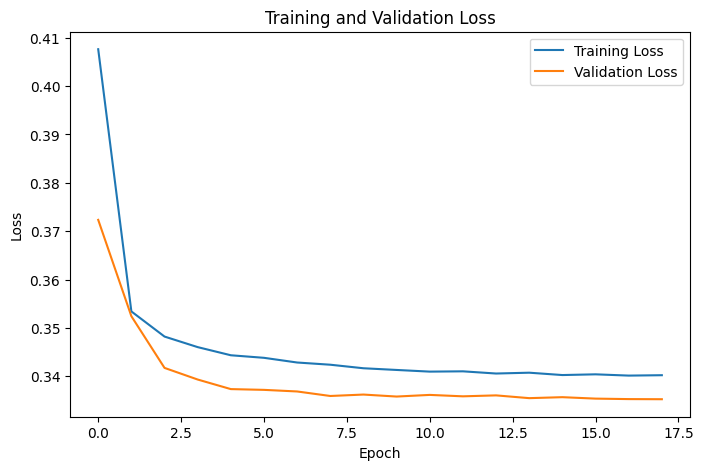

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.show()

# PR-AUC

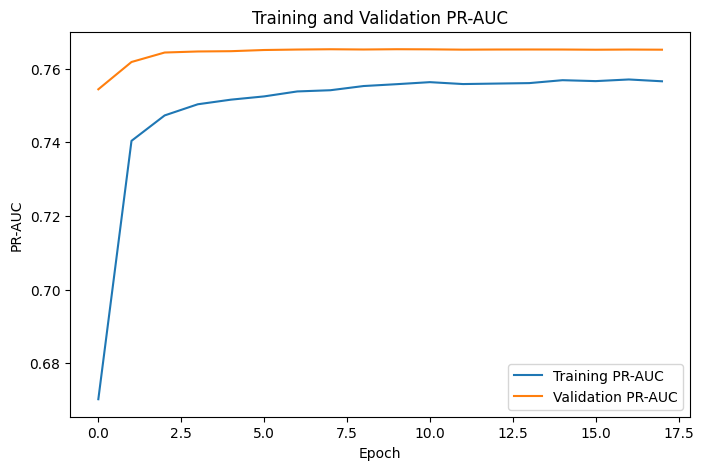

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["pr_auc"],
    label="Training PR-AUC"
)

plt.plot(
    history.history["val_pr_auc"],
    label="Validation PR-AUC"
)

plt.xlabel("Epoch")
plt.ylabel("PR-AUC")
plt.title(
    "Training and Validation PR-AUC"
)

plt.legend()

plt.show()

In [33]:
test_prob = model.predict(
    [
        A_test,
        S_test,
        M_test
    ],
    batch_size=4096,
    verbose=1
).ravel()

test_pred = (
    test_prob >= 0.5
).astype(int)

25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step


In [34]:
accuracy = accuracy_score(
    y_test,
    test_pred
)

precision = precision_score(
    y_test,
    test_pred
)

recall = recall_score(
    y_test,
    test_pred
)

f1 = f1_score(
    y_test,
    test_pred
)

roc_auc = roc_auc_score(
    y_test,
    test_prob
)

pr_auc = average_precision_score(
    y_test,
    test_prob
)

balanced_acc = balanced_accuracy_score(
    y_test,
    test_pred
)

cm = confusion_matrix(
    y_test,
    test_pred
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (
    tn + fp
)

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "PR-AUC",
        "Specificity",
        "Balanced Accuracy"
    ],

    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc,
        specificity,
        balanced_acc
    ]
})

display(
    results.round(4)
)

,Metric,Score
0,Accuracy,0.8474
1,Precision,0.7405
2,Recall,0.5998
3,F1-score,0.6628
4,ROC-AUC,0.8978
5,PR-AUC,0.7641
6,Specificity,0.9299
7,Balanced Accuracy,0.7649


In [35]:
print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            "Low Risk",
            "High Risk"
        ]
    )
)

              precision    recall  f1-score   support

    Low Risk       0.87      0.93      0.90     75000
   High Risk       0.74      0.60      0.66     25000

    accuracy                           0.85    100000
   macro avg       0.81      0.76      0.78    100000
weighted avg       0.84      0.85      0.84    100000



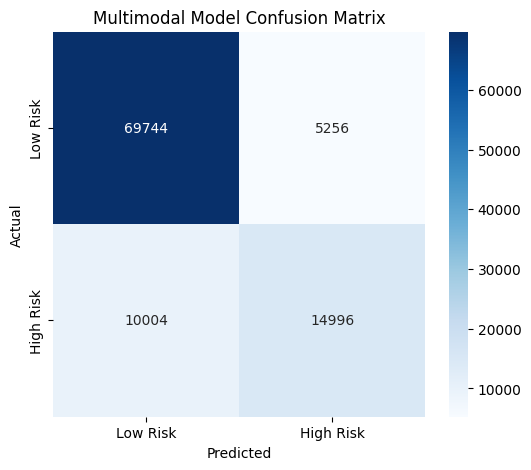

In [36]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Low Risk",
        "High Risk"
    ],
    yticklabels=[
        "Low Risk",
        "High Risk"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "Multimodal Model Confusion Matrix"
)

plt.show()

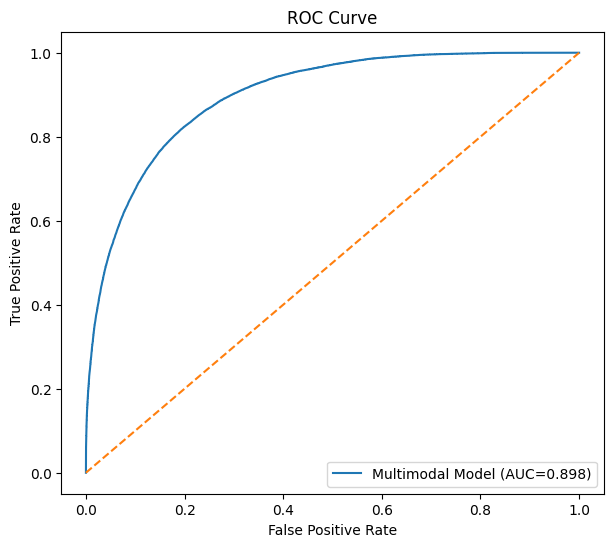

In [37]:
fpr, tpr, _ = roc_curve(
    y_test,
    test_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Multimodal Model (AUC={roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve"
)

plt.legend()

plt.show()

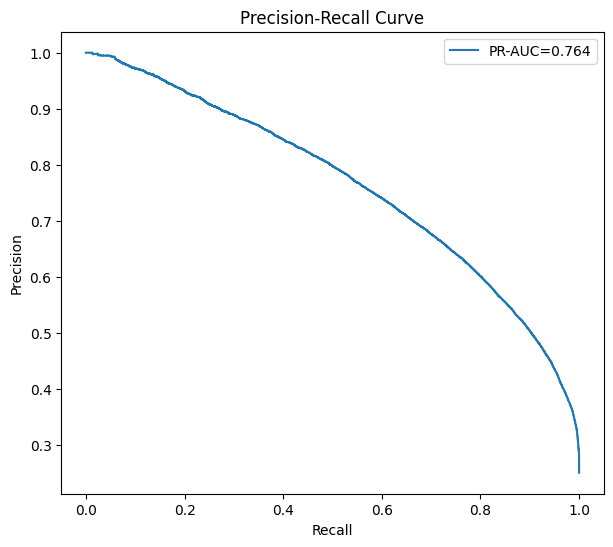

In [38]:
precision_curve, recall_curve, _ = (
    precision_recall_curve(
        y_test,
        test_prob
    )
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"PR-AUC={pr_auc:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curve"
)

plt.legend()

plt.show()

In [39]:
model.save(
    "/content/multimodal_student_risk_model.keras"
)

print("Model saved successfully.")

Model saved successfully.


In [40]:
def build_branch_model(
    input_dims,
    branch_name="single"
):

    inp = Input(
        shape=(input_dims,),
        name=branch_name
    )

    x = Dense(
        128,
        activation="relu"
    )(inp)

    x = BatchNormalization()(x)

    x = Dropout(0.30)(x)

    x = Dense(
        64,
        activation="relu"
    )(x)

    x = Dropout(0.30)(x)

    out = Dense(
        1,
        activation="sigmoid"
    )(x)

    m = Model(
        inputs=inp,
        outputs=out
    )

    m.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.AUC(
                name="roc_auc"
            ),
            tf.keras.metrics.AUC(
                name="pr_auc",
                curve="PR"
            )
        ]
    )

    return m

In [41]:
academic_model = build_branch_model(
    A_train.shape[1],
    "academic_only"
)

academic_model.fit(
    A_train,
    y_train,
    validation_data=(
        A_val,
        y_val
    ),
    epochs=15,
    batch_size=2048,
    callbacks=callbacks,
    verbose=1
)

academic_prob = academic_model.predict(
    A_test,
    batch_size=4096
).ravel()

academic_pred = (
    academic_prob >= 0.5
).astype(int)

Epoch 1/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - loss: 0.5447 - pr_auc: 0.4199 - roc_auc: 0.6962 - val_loss: 0.5520 - val_pr_auc: 0.4877 - val_roc_auc: 0.7425 - learning_rate: 0.0010
Epoch 2/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.5015 - pr_auc: 0.4704 - roc_auc: 0.7295 - val_loss: 0.5051 - val_pr_auc: 0.4980 - val_roc_auc: 0.7476 - learning_rate: 0.0010
Epoch 3/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4948 - pr_auc: 0.4824 - roc_auc: 0.7371 - val_loss: 0.4902 - val_pr_auc: 0.5006 - val_roc_auc: 0.7492 - learning_rate: 0.0010
Epoch 4/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4928 - pr_auc: 0.4861 - roc_auc: 0.7395 - val_loss: 0.4873 - val_pr_auc: 0.5014 - val_roc_auc: 0.7500 - learning_rate: 5.0000e-04
Epoch 5/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4916 - pr_auc: 0.4881 - roc_auc: 0.7410 - val_loss: 0.4870 - val_pr_auc: 0.5006 - val_roc_auc: 0.7501 - learning_rate: 5.0000e-04
Epoch 6/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/ste

In [42]:
academic_result = {
    "Model": "Academic Only",
    "Accuracy": accuracy_score(
        y_test,
        academic_pred
    ),
    "Precision": precision_score(
        y_test,
        academic_pred
    ),
    "Recall": recall_score(
        y_test,
        academic_pred
    ),
    "F1": f1_score(
        y_test,
        academic_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_test,
        academic_prob
    ),
    "PR-AUC": average_precision_score(
        y_test,
        academic_prob
    )
}

print(academic_result)

{'Model': 'Academic Only', 'Accuracy': 0.76787, 'Precision': 0.5980898012954221, 'Recall': 0.21792, 'F1': 0.31944648040106716, 'ROC-AUC': np.float64(0.7421621578666666), 'PR-AUC': np.float64(0.4870828190832815)}


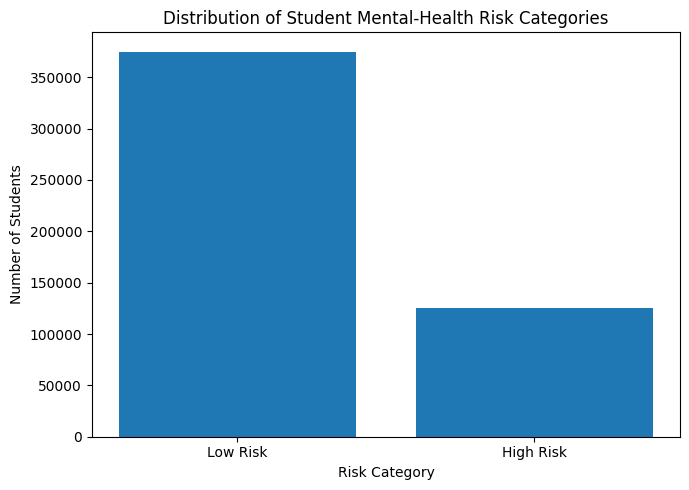

In [43]:
# ============================================================
# FIGURE 1: TARGET CLASS DISTRIBUTION
# ============================================================

class_counts = df["risk_target"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Low Risk", "High Risk"],
    class_counts.values
)

plt.xlabel("Risk Category")
plt.ylabel("Number of Students")
plt.title("Distribution of Student Mental-Health Risk Categories")

plt.tight_layout()
plt.show()

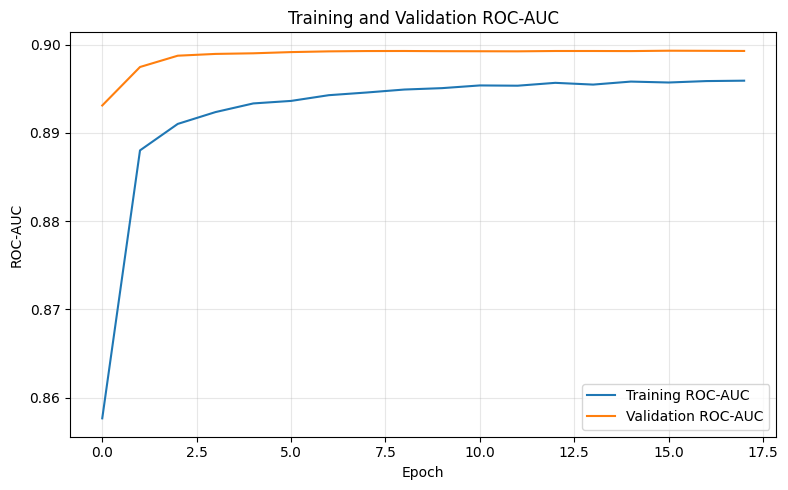

In [44]:
# ============================================================
# FIGURE 2: TRAINING AND VALIDATION ROC-AUC
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["roc_auc"],
    label="Training ROC-AUC"
)

plt.plot(
    history.history["val_roc_auc"],
    label="Validation ROC-AUC"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("Training and Validation ROC-AUC")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

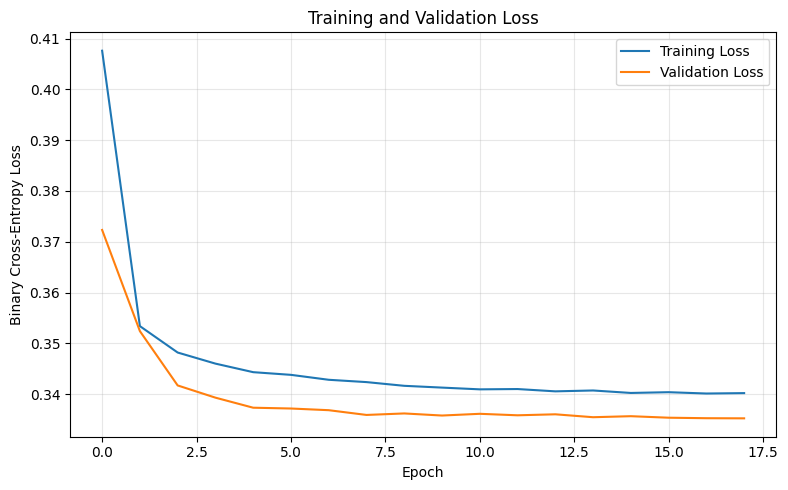

In [45]:
# ============================================================
# TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

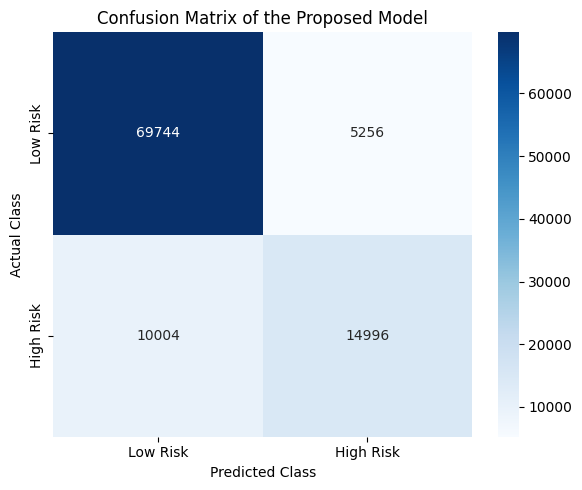

In [46]:
# ============================================================
# FIGURE 3: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    test_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Low Risk",
        "High Risk"
    ],
    yticklabels=[
        "Low Risk",
        "High Risk"
    ]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix of the Proposed Model")

plt.tight_layout()
plt.show()

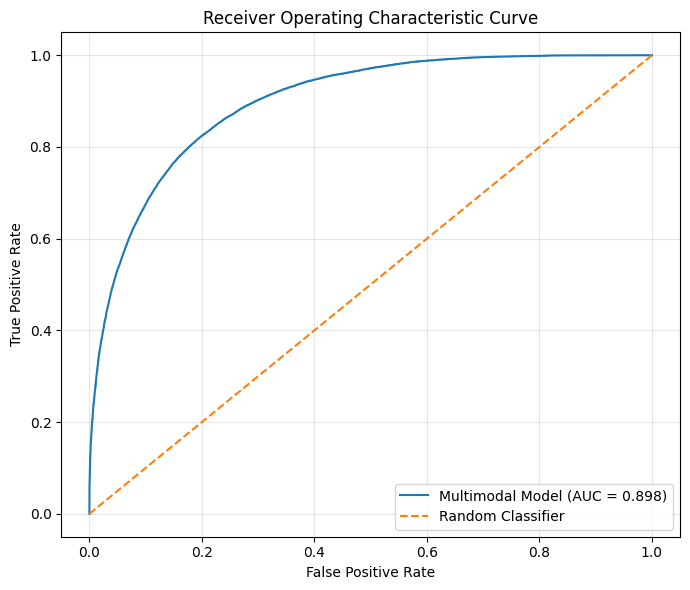

In [47]:
# ============================================================
# FIGURE 4: ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    test_prob
)

roc_auc = roc_auc_score(
    y_test,
    test_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Multimodal Model (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("Receiver Operating Characteristic Curve")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

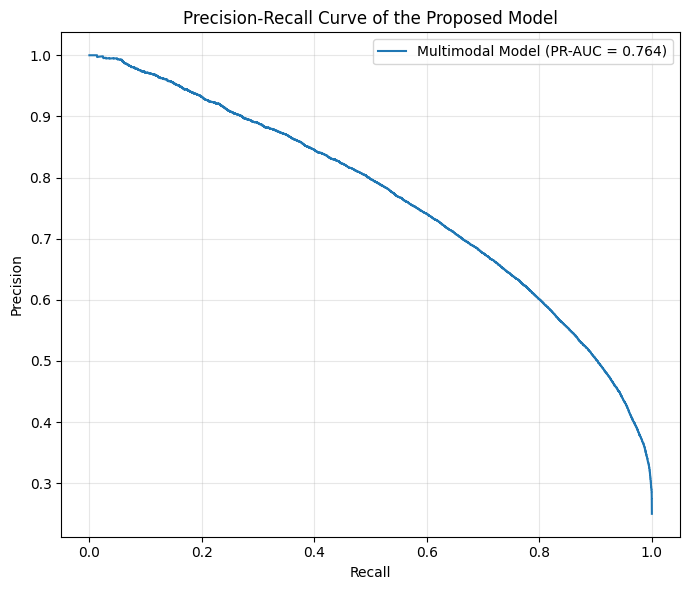

In [48]:
# ============================================================
# FIGURE 5: PRECISION-RECALL CURVE
# ============================================================

precision_curve, recall_curve, thresholds_pr = (
    precision_recall_curve(
        y_test,
        test_prob
    )
)

pr_auc = average_precision_score(
    y_test,
    test_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Multimodal Model (PR-AUC = {pr_auc:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curve of the Proposed Model"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()